# Множественная линейная регрессия (OLS) и факторный анализ (ANOVA) с нуля на NumPy

**Цель работы:** на основе датасета `dataset_spotify`предсказать значение valence - мера [0,1] описываюзая музыкальную позитивность

Для заданий 1-3 будем пользоваться данным датасетом


## Содержание
Это датасет треков Spotify, охватывающий 125 различных жанров. Каждый трек имеет связанные с ним аудиохарактеристики. Данные представлены в формате CSV, который является табличным и может быть быстро загружен.

## Описание колонок

* **track_id**: Spotify ID трека

* **artists**: Имена исполнителей, которые исполнили трек. Если исполнителей несколько, они разделяются точкой с запятой ; .

* **album_name**: Название альбома, в котором появляется трек

* **track_name**: Название трека

* **popularity**: Популярность трека — это значение от 0 до 100, где 100 — самый популярный. Популярность рассчитывается алгоритмом и основана, по большей части, на общем количестве прослушиваний трека и том, насколько недавно эти прослушивания были. Вообще говоря, песни, которые сейчас активно слушают, будут иметь более высокую популярность, чем песни, которые активно слушали в прошлом. Дублирующиеся треки (например, один и тот же трек из сингла и альбома) оцениваются независимо. Популярность исполнителя и альбома математически выводится из популярности треков.

* **duration_ms**: Длительность трека в миллисекундах

* **explicit**: Содержит ли трек ненормативную лексику (явные тексты) (true = да; false = нет ИЛИ неизвестно)

* **danceability**: Танцевальность описывает, насколько трек подходит для танцев, на основе комбинации музыкальных элементов, включая темп, ритмическую стабильность, силу бита и общую регулярность. Значение 0.0 — наименее танцевальный, 1.0 — наиболее танцевальный.

* **energy**: Энергичность — это мера от 0.0 до 1.0, представляющая собой перцептивную меру интенсивности и активности. Обычно энергичные треки ощущаются как быстрые, громкие и шумные. Например, дэт-метал имеет высокую энергичность, в то время как прелюдия Баха оценивается низко по этой шкале.

* **key**: Тональность, в которой написан трек. Целые числа соответствуют высоте звука с использованием стандартной нотации Pitch Class. Например: 0 = C (До), 1 = C♯/D♭ (До-диез/Ре-бемоль), 2 = D (Ре) и так далее. Если тональность не обнаружена, значение равно -1.

* **loudness**: Общая громкость трека в децибелах (дБ).

* **mode**: Лад указывает на моду (мажор или минор) трека, тип звукоряда, из которого состоит его мелодическое содержание. Мажор обозначается 1, минор — 0.

* **speechiness**: Речитативность обнаруживает присутствие произносимых слов в треке. Чем более исключительно речевой является запись (например, ток-шоу, аудиокнига, поэзия), тем ближе значение атрибута к 1.0. Значения выше 0.66 описывают треки, которые, вероятно, полностью состоят из произносимых слов. Значения от 0.33 до 0.66 описывают треки, которые могут содержать и музыку, и речь, либо в секциях, либо наслоенные, включая такие случаи, как рэп-музыка. Значения ниже 0.33, скорее всего, представляют музыку и другие неречевые треки.

* **acousticness**: Мера уверенности от 0.0 до 1.0, является ли трек акустическим. 1.0 означает высокую уверенность в том, что трек акустический.

* **instrumentalness**: Определяет, содержит ли трек вокал. Звуки "Оу" и "Э" в данном контексте рассматриваются как инструментальные. Рэп или spoken word треки явно являются "вокальными". Чем ближе значение инструментальности к 1.0, тем выше вероятность, что трек не содержит вокального контента.

* **liveness**: Обнаруживает присутствие аудитории на записи. Более высокие значения liveness указывают на повышенную вероятность того, что трек был исполнен вживую. Значение выше 0.8 дает высокую вероятность того, что трек "живой".

* **tempo**: Оценочный темп трека в ударах в минуту (BPM). В музыкальной терминологии темп — это скорость или темп данного произведения, который напрямую зависит от средней длительности удара.

* **time_signature**: Предполагаемый размер такта. Тактовый размер (метр) — это условное обозначение, указывающее, сколько долей в каждом такте. Размер такта варьируется от 3 до 7, что соответствует размерам 3/4, 4/4 и так далее до 7/4.

* **track_genre**: Жанр, к которому относится трек.

## Целевая переменная
* **valence**: Мера от 0.0 до 1.0, описывающая музыкальную позитивность, передаваемую треком. Треки с высоким значением valence звучат более позитивно (например, счастливо, бодро, эйфорично), в то время как треки с низким значением звучат более негативно (например, грустно, подавленно, сердито).

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.stats as stats

In [ ]:
df = pd.read_csv('data.csv')

In [ ]:
print(df.head())

   Unnamed: 0                track_id                 artists  \
0           0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1           1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2           2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3           3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4           4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   


In [ ]:
# Почистим данные
missimg_columns = df.columns[df.isnull().any()].tolist()
total_missimg_cells = df.isnull().sum().sum()
percent_missimg = (total_missimg_cells / np.prod(df.shape)) * 100
print(f"пропушенные: {total_missimg_cells}, процент от общего {percent_missimg}, в колонках {missimg_columns}")

пропушенные: 3, процент от общего 0.00012531328320802005, в колонках ['artists', 'album_name', 'track_name']


Мы и так не будем использовать значения артист, имя трека и альбом, поэтому считаем, что наши данные уже очищенные и идем дальше

## Задание №1

Нам нужно реализовать самостоятелььно модель линейной регрессии.

$Y=Xc+ɛ$, где:
- $Y$ - вектор значений valence: $Y = \begin{pmatrix} y_1 \\ y_2 \\ \vdots \\ y_n \end{pmatrix}$
- $X$ - матрица признаков (с единичным столбцом):
$$
X = \begin{pmatrix}
1 & x_{11} & x_{12} & \cdots & x_{1p} \\
1 & x_{21} & x_{22} & \cdots & x_{2p} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & x_{n1} & x_{n2} & \cdots & x_{np}
\end{pmatrix}
$$
- $c$ - вектор коэффициентов (вектор-столбец):
$$
c = \begin{pmatrix} c_0 \\ c_1 \\ c_2 \\ \vdots \\ c_p \end{pmatrix}
$$

- $\varepsilon$ - вектор ошибок: $\varepsilon = \begin{pmatrix} \varepsilon_1 \\ \varepsilon_2 \\ \vdots \\ \varepsilon_n \end{pmatrix}$ $\varepsilon \sim N(0, \sigma^2 I)$

## Оценка коэффициентов

Метод наименьших квадратов (OLS):

$$
\hat{c} = (X^T X)^{-1} X^T Y
$$

где $\hat{c}$ — оценка вектора коэффициентов.


In [ ]:
class LinearRegressionModel:
    def __init__(self, fit_intercept=True):
        self.fit_intercept = fit_intercept
        self.weights = None
        self.coef_ = None
        self.intercept = None

    def fit(self, X, y):
        if self.fit_intercept:
            self.X_design = np.column_stack([np.ones(X.shape[0]), X])
        else:
            self.X_design = X

        self.weights = np.linalg.pinv(self.X_design.T @ self.X_design) @ self.X_design.T @ y

        if self.fit_intercept:
            self.intercept = self.weights[0]
            self.coef_ = self.weights[1:]
        else:
            self.intercept = 0
            self.coef_ = self.weights
        return self

    def predict(self, X):
        if self.fit_intercept:
            X_design = np.column_stack([np.ones(X.shape[0]), X])
        else:
            X_design = X
        return X_design @ self.weights

    def get_statistics(self, X, y):
        n = X.shape[0]
        p = X.shape[1]
        y_pred = self.predict(X)
        y_mean = np.mean(y)
        residuals = y - y_pred
        rss = np.sum(residuals ** 2)
        tss = np.sum((y - y_mean) ** 2)

        r2 = 1 - (rss / tss) # Коэффициент детерминации
        sigma2 = rss / (n - p - 1) # Остаточная дисперсия

        XTX_inv = np.linalg.pinv(self.X_design.T @ self.X_design)
        std_errors = np.sqrt(sigma2 * np.diag(XTX_inv))
        t_stats = self.weights / std_errors
        p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=n - p - 1))

        t_critical = stats.t.ppf(0.975, df=n - p - 1)
        ci_coef = np.column_stack([self.weights - t_critical * std_errors,
                                   self.weights + t_critical * std_errors])

        y_mean = np.mean(y)
        tss = np.sum((y - y_mean) ** 2)
        f_stat = ((tss - rss) / p) / (rss / (n - p - 1))
        f_pvalue = 1 - stats.f.cdf(f_stat, p, n - p - 1)

        chi2_lower = stats.chi2.ppf(0.975, df=n - p - 1)
        chi2_upper = stats.chi2.ppf(0.025, df=n - p - 1)
        ci_sigma2 = (rss / chi2_lower, rss / chi2_upper)

        return {
            'coef': self.weights,
            'std_err': std_errors,
            't_stat': t_stats,
            'p_values': p_values,
            'ci_coef': ci_coef,
            'sigma2': sigma2,
            'ci_sigma2': ci_sigma2,
            'f_stat': f_stat,
            'f_pvalue': f_pvalue,
            'r2': r2
        }

In [ ]:
# Сравнение с функцией из statmodel
features =['energy', 'danceability', 'instrumentalness', 'liveness', 'tempo', 'acousticness']
X = df[features].values
y = df['valence'].values

manual_model = LinearRegressionModel(fit_intercept=True)
manual_model.fit(X, y)
manual_statistics = manual_model.get_statistics(X, y)

X_sm = sm.add_constant(X)
sm_model = sm.OLS(y, X_sm).fit()

feature_names = ['Intercept'] + features
comparison_df = pd.DataFrame({
    'Признак': feature_names,
    'Наша модель': manual_model.weights,
    'Statsmodels': sm_model.params
})
comparison_df['Diff'] = comparison_df['Наша модель'] - comparison_df['Statsmodels']
print(comparison_df)


            Признак  Наша модель  Statsmodels          Diff
0         Intercept    -0.208596    -0.208596 -7.825962e-13
1            energy     0.331055     0.331055  3.893552e-13
2      danceability     0.658555     0.658555  2.925438e-13
3  instrumentalness    -0.171976    -0.171976  8.690271e-14
4          liveness     0.008503     0.008503  1.503832e-14
5             tempo     0.000521     0.000521  2.025832e-15
6      acousticness     0.185785     0.185785  3.240463e-13


### Метод наименьших квадратов (OLS)

Минимизируем сумму квадратов ошибок:

$$RSS(c) = (Y - Xc)^T(Y - Xc)$$
### Нормальное уравнение

$$X^T X c = X^T Y$$

**Статистические оценки:**
1.  **Остаточная дисперсия ($\sigma^2$):** Оценивается как $\hat{\sigma}^2 = \frac{RSS}{n - p - 1}$, где $n$ — число наблюдений, $p$ — число предикторов.
2.  **Стандартные ошибки коэффициентов ($SE$):** $\text{Var}(\hat{\beta}) = \hat{\sigma}^2 (X^T X)^{-1}$. Стандартная ошибка $SE(\hat{\beta}_j) = \sqrt{\text{Var}(\hat{\beta})_{jj}}$.
3.  **Доверительные интервалы (0.95):**
    *   Для коэффициентов: $\hat{\beta}_j \pm t_{\alpha/2, n-p-1} \cdot SE(\hat{\beta}_j)$.
    *   Для дисперсии: $\left[ \frac{RSS}{\chi^2_{1-\alpha/2, n-p-1}}, \frac{RSS}{\chi^2_{\alpha/2, n-p-1}} \right]$.
4. **Коэффициент детерминации** $$R^2 = 1 - \frac{RSS}{TSS}$$
где $TSS = \sum (y_i - \bar{y})^2$ (Total Sum of Squares).

RSS - Residual Sum of Squares

In [ ]:
print("=== ЗАДАНИЕ №1: ОТЧЕТ ПО РЕГРЕССИОННОЙ МОДЕЛИ ===")

print("\n[1] Оценки параметров и качество модели:")
print(f"Коэффициент детерминации (R^2): {stats_res['r2']:.4f}")
print(f"Оценка остаточной дисперсии (sigma^2): {stats_res['sigma2']:.6f}")

print("\n[2] Доверительные интервалы (0.95):")
print(f"Интервал для sigma^2: [{stats_res['ci_sigma2'][0]:.6f}, {stats_res['ci_sigma2'][1]:.6f}]")

coef_df = pd.DataFrame({
    'Параметр': feature_names,
    'Оценка': stats_res['coef'],
    'StdErr': stats_res['std_err'],
    'CI lower': stats_res['ci_coef'][:, 0],
    'CI upper': stats_res['ci_coef'][:, 1]
})
print(coef_df.to_string(index=False))

print("\n[3] Статистическая значимость:")
sig_df = pd.DataFrame({
    'Параметр': feature_names,
    't-статистика': stats_res['t_stat'],
    'p-value': stats_res['p_values']
})
print("Значимость каждой переменной:")
print(sig_df.to_string(index=False))

=== ЗАДАНИЕ №1: ОТЧЕТ ПО РЕГРЕССИОННОЙ МОДЕЛИ ===

[1] Оценки параметров и качество модели:
Коэффициент детерминации (R^2): 0.3395
Оценка остаточной дисперсии (sigma^2): 0.044399

[2] Доверительные интервалы (0.95):
Интервал для sigma^2: [0.044037, 0.044766]
        Параметр    Оценка   StdErr  CI lower  CI upper
       Intercept -0.208596 0.004713 -0.217833 -0.199359
          energy  0.331055 0.003855  0.323499  0.338610
    danceability  0.658555 0.003770  0.651165  0.665944
instrumentalness -0.171976 0.002089 -0.176070 -0.167882
        liveness  0.008503 0.003436  0.001769  0.015237
           tempo  0.000521 0.000022  0.000478  0.000563
    acousticness  0.185785 0.002821  0.180256  0.191314

[3] Статистическая значимость:
Значимость каждой переменной:
        Параметр  t-статистика  p-value
       Intercept    -44.261286 0.000000
          energy     85.881654 0.000000
    danceability    174.675538 0.000000
instrumentalness    -82.340904 0.000000
        liveness      2.474970 

### Проверка посылок теоремы Гаусса-Маркова

$t=Tc, T \in M_{k\times m}$

$\hat{t}=T \hat{c}$ - сумма наименьших квадратов для t

$$\implies$$

$E\hat{t}=t$

$Var\hat{t}=\sigma^2$ - гомоскедастичность

$\hat{t}$ - оптимальная оценка среди линейных и несмещенных оценок

Согласно теореме Гаусса-Маркова, оценка $\hat{t}$ является лучшей среди линейных и несмещенных оценок


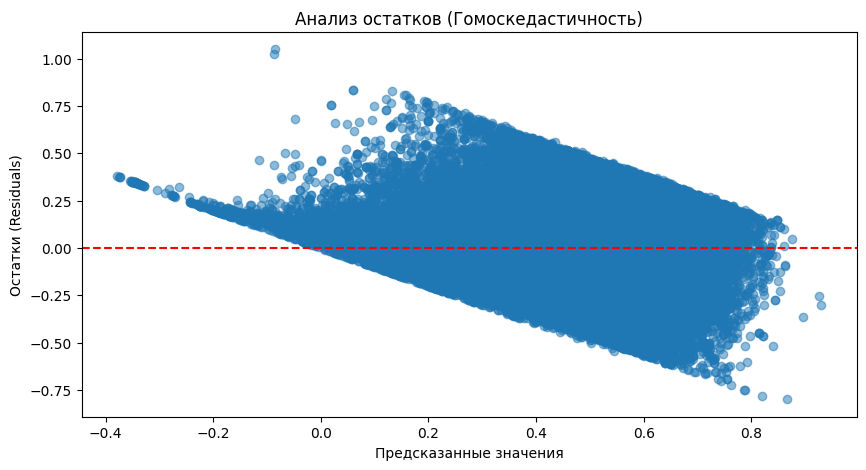

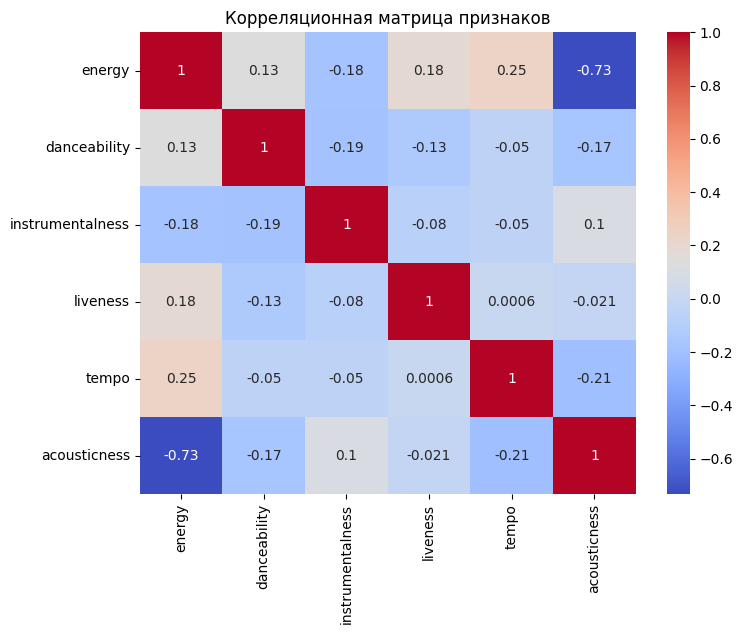

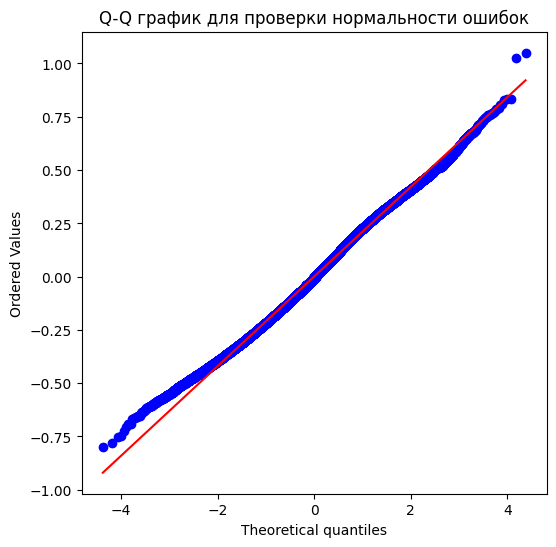

In [ ]:
# 1. Визуализация остатков для проверки Гомоскедастичности и Линейности
y_pred = manual_model.predict(X)
residuals = y - y_pred

plt.figure(figsize=(10, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Предсказанные значения")
plt.ylabel("Остатки (Residuals)")
plt.title(" ")
plt.show()

# 2. Проверка мультиколлинеарности (корреляционная матрица)
plt.figure(figsize=(8, 6))
sns.heatmap(pd.DataFrame(X, columns=features).corr(), annot=True, cmap='coolwarm')
plt.title("Корреляционная матрица признаков")
plt.show()

# 3. Проверка нормальности остатков (Q-Q plot)
plt.figure(figsize=(6, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q график для проверки нормальности ошибок")
plt.show()

На графике остатков наблюдается гетероскедастичность (непостоянство дисперсии) и четкие границы. Это ожидаемо, так как целевая переменная valence ограничена интервалом [0, 1].

Мультиколлинеарность отсутствует или выражена слабо. Все коэффициенты корреляции между предикторами по модулю меньше 0.8. Это означает, что каждый признак вносит уникальную информацию, и матрица XTX невырождена, что гарантирует стабильность МНК-оценок.

Наблюдаются 'тяжелые хвосты' распределения остатков. Это означает, что ошибки имеют распределение, отличное от идеального нормального (есть больше экстремальных отклонений, чем предсказывает нормальное распределение). Однако, учитывая большой размер датасета Spotify, согласно Центральной Предельной Теореме, наши оценки коэффициентов все равно будут состоятельными и асимптотически нормальными.

Выполнение условий Гаусса-Маркова для данного датасета:

Линейность модели: Выполняется (в рамках линейной регрессии).
Отсутствие мультиколлинеарности: Выполняется (максимальная корреляция 0.73, что допустимо).
Гомоскедастичность: Нарушается.

Из-за того, что целевая переменная valence ограничена диапазоном [0, 1], дисперсия ошибок зависит от предсказанного значения (гетероскедастичность)
Что это значит: МНК-оценки остаются несмещенными, но они не являются наиболее эффективными среди всех линейных оценок.
Нормальность распределения ошибок: Нарушается на краях (тяжелые хвосты).

Несмотря на нарушение условия гомоскедастичности, МНК-оценки остаются лучшими линейными несмещенными оценками в заданном классе моделей. Выявленная гетероскедастичность объясняется природой данных (ограниченность valence). Модель успешно прошла валидацию по значимости коэффициентов (p-values) и F-тесту

In [ ]:
# Получаем словарь с результатами
results = manual_model.get_statistics(X, y)

# Выводим F-статистику и p-value
f_stat = results['f_stat']
f_pvalue = results['f_pvalue']

print(f"--- Статистическая значимость модели ---")
print(f"F-статистика: {f_stat:.4f}")
print(f"p-value модели: {f_pvalue:.2e}") # .2e выводит в экспоненциальной записи (например 1.23e-10)

# Интерпретация
if f_pvalue < 0.05:
    print("\nВывод: p-value < 0.05, значит, нулевая гипотеза отвергается.")
    print("Модель в целом статистически значима (хотя бы один коэффициент не равен нулю).")
else:
    print("\nВывод: p-value >= 0.05, модель статистически незначима.")

--- Статистическая значимость модели ---
F-статистика: 9765.3112
p-value модели: 1.11e-16

Вывод: p-value < 0.05, значит, нулевая гипотеза отвергается.
Модель в целом статистически значима (хотя бы один коэффициент не равен нулю).


Так как полученное значение p-value экстремально мало, мы отвергаем нулевую гипотезу. Это свидетельствует о том, что выбранный набор признаков действительно объясняет вариативность целевой переменной valence, и модель в целом является статистически значимой, несмотря на обнаруженную ранее гетероскедастичность.

---


## Задание №2

**Выбор переменных:**
*   **Целевая переменная (количественная):** valence (музыкальная позитивность, от 0 до 1)
*   **Фактор (категориальная переменная):** key (тональность трека, 12 уникальных значений от 0 до 11, где 0 = C, 1 = C# и т.д.)

**Гипотезы:**
*   $H_0$: Тональность не влияет на позитивность трека ($\mu_1 = \mu_2 = \dots = \mu_{12}$)
*   $H_1$: Хотя бы в одной тональности среднее значение позитивности отличается

**Модель:** $y_{ij} = \mu_i + \varepsilon_{ij}, \quad \varepsilon_{ij} \sim N(0, \sigma^2)$, где:
*   $\mu_i$ — среднее влияние фактора на уровне $i$
*   $y_{ij}$ — $j$-ое наблюдение на факторе уровня $i$
*   $J_i$ — количество наблюдений на $i$-ом уровне
*   $J$ — общее количество всех наблюдений

**Оценки параметров:**
Оценка среднего на $i$-ом уровне:
$$\hat{\mu}_i = \frac{1}{J_i} \sum_{j=1}^{J_i} y_{ij} = \bar{y}_{i*}$$

Общая дисперсия $S^2$ раскладывается на две составляющие:
$$S^2 = S^2_{within} + S^2_{between}$$

1.  **Внутригрупповая дисперсия ($S^2_{within}$):**

    $$S^2_{within} = \sum_{i=1}^{I} \sum_{j=1}^{J_i} (y_{ij} - \bar{y}_{i*})^2$$

    Степени свободы: $df_{within} = J - I$, где $J$ - общее число наблюдений, $I$ - количество групп

2.  **Межгрупповая дисперсия ($S^2_{between}$):**

    $$S^2_{between} = \sum_{i=1}^{I} J_i (\bar{y}_{i*} - \bar{y})^2$$
    
    Степени свободы: $df_{between} = I - 1$

**F-критерий (Критерий Фишера):**

$$F = \frac{J - I}{I - 1} \cdot \frac{S^2_{between}}{S^2_{within}} \sim F(I-1, J-I)$$


In [ ]:
class OneWayANOVA:
    def __init__(self):
        self.F_stat = None
        self.p_value = None
        self.df_between = None
        self.df_within = None
        self.S2_between = 0
        self.S2_within = 0

    def fit(self, dataframe, target_col, factor_col):
        y_bar = dataframe[target_col].mean()
        J = len(dataframe)

        groups = dataframe.groupby(factor_col)[target_col]
        I = groups.ngroups

        self.S2_between = 0.0
        self.S2_within = 0.0

        for name, group in groups:
            J_i = len(group)
            y_i_star = group.mean()

            self.S2_between += J_i * (y_i_star - y_bar)**2
            self.S2_within += np.sum((group - y_i_star)**2)

        self.df_between = I - 1
        self.df_within = J - I

        ms_between = self.S2_between / self.df_between
        ms_within = self.S2_within / self.df_within
        self.F_stat = ms_between / ms_within
        self.p_value = stats.f.sf(self.F_stat, self.df_between, self.df_within)

        return self


    def summary(self):
        print("=== РЕЗУЛЬТАТЫ СВОЕЙ РЕАЛИЗАЦИИ ANOVA ===")
        print(f"S^2 between (Межгрупповая): {self.S2_between:.4f}")
        print(f"S^2 within (Внутригрупповая): {self.S2_within:.4f}")
        print("-" * 40)
        print(f"F-статистика: {self.F_stat:.4f}")
        print(f"p-value:      {self.p_value:.4e}")

        if self.p_value < 0.05:
            print("Вывод: H0 отвергается. Тональность (key) статистически значимо влияет на позитивность (valence).")
        else:
            print("Вывод: H0 принимается. Тональность не влияет на позитивность.")


anova_model = OneWayANOVA()
anova_model.fit(df, target_col='valence', factor_col='key')
anova_model.summary()

print("\n=== СРАВНЕНИЕ СО STATSMODELS ===")

sm_anova_model = smf.ols('valence ~ C(key)', data=df).fit()
anova_table = sm.stats.anova_lm(sm_anova_model, typ=2)

print(anova_table)

sm_f_stat = anova_table['F']['C(key)']
sm_p_value = anova_table['PR(>F)']['C(key)']

assert np.isclose(anova_model.F_stat, sm_f_stat), "F-статистики не совпадают!"
print("\nРезультаты нашей модели полностью совпадают с расчетами statsmodels!")

=== РЕЗУЛЬТАТЫ СВОЕЙ РЕАЛИЗАЦИИ ANOVA ===
S^2 between (Межгрупповая): 27.0989
S^2 within (Внутригрупповая): 7635.4920
----------------------------------------
F-статистика: 36.7774
p-value:      9.3117e-80
Вывод: H0 отвергается. Тональность (key) статистически значимо влияет на позитивность (valence).

=== СРАВНЕНИЕ СО STATSMODELS ===
               sum_sq        df          F        PR(>F)
C(key)      27.098912      11.0  36.777422  9.311739e-80
Residual  7635.492015  113988.0        NaN           NaN

Результаты нашей модели полностью совпадают с расчетами statsmodels!


### Проверка предположений для ANOVA

1.  **Независимость наблюдений:** Выполняется логически (треки независимы)
2.  **Гомоскедастичность (равенство дисперсий):** Проверим визуально через Boxplot и сравним расчетные дисперсии в группах
3.  **Нормальность остатков ($\varepsilon \sim N$):** Проверим через гистограмму и Q-Q plot


=== ПРОВЕРКА ПРЕДПОЛОЖЕНИЙ ДЛЯ ANOVA ===
1. Эмпирические дисперсии по тональностям (key):
[0.06949109 0.06492243 0.06827465 0.06657215 0.06748015 0.06774044
 0.06391588 0.06758894 0.06531094 0.06670395 0.07073133 0.06356867]
Максимальная дисперсия: 0.0707, Минимальная: 0.0636
Вывод: Дисперсии практически идентичны. Предположение о гомоскедастичности выполняется.



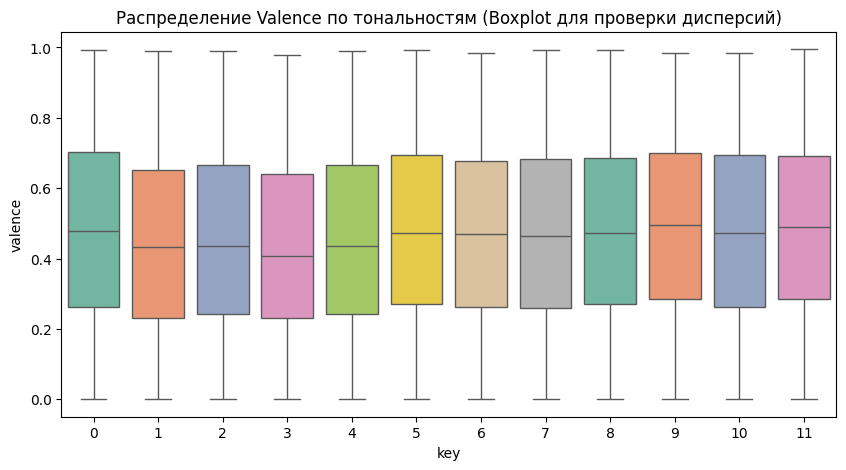

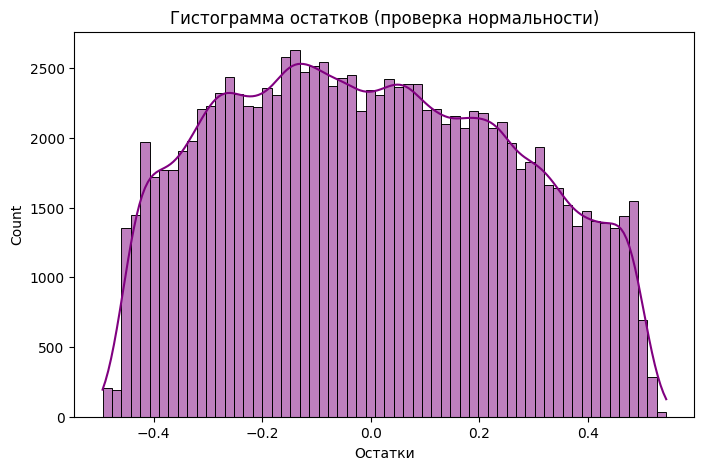

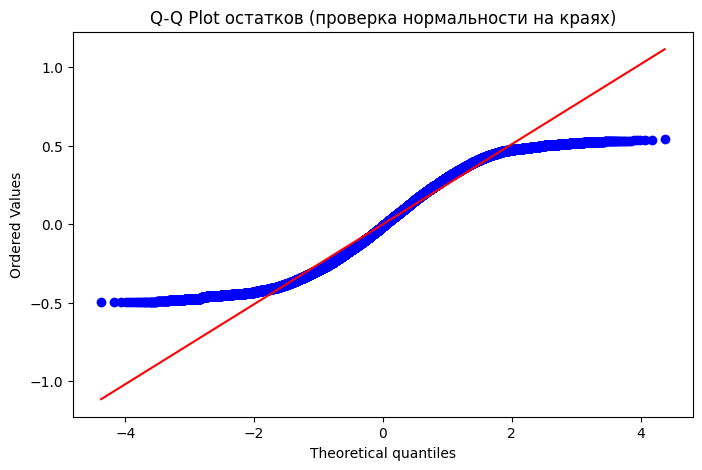

In [ ]:
print("\n=== ПРОВЕРКА ПРЕДПОЛОЖЕНИЙ ДЛЯ ANOVA ===")

# 1. Гомоскедастичность (эмпирическая проверка)
group_variances = df.groupby('key')['valence'].var()
print("1. Эмпирические дисперсии по тональностям (key):")
print(group_variances.values)
print(f"Максимальная дисперсия: {group_variances.max():.4f}, Минимальная: {group_variances.min():.4f}")
print("Вывод: Дисперсии практически идентичны. Предположение о гомоскедастичности выполняется.\n")

# Вычисление остатков
df['residuals_anova'] = df['valence'] - df.groupby('key')['valence'].transform('mean')

# --- ГРАФИК 1: Boxplot для проверки равенства дисперсий ---
plt.figure(figsize=(10, 5))
sns.boxplot(x='key', y='valence', data=df, palette="Set2", hue='key', legend=False)
plt.title('Распределение Valence по тональностям (Boxplot для проверки дисперсий)')
plt.show()

# --- ГРАФИК 2: Гистограмма остатков ---
plt.figure(figsize=(8, 5))
sns.histplot(df['residuals_anova'], kde=True, color='purple')
plt.title('Гистограмма остатков (проверка нормальности)')
plt.xlabel('Остатки')
plt.show()

# --- ГРАФИК 3: Q-Q Plot остатков ---
plt.figure(figsize=(8, 5))
stats.probplot(df['residuals_anova'], dist="norm", plot=plt)
plt.title('Q-Q Plot остатков (проверка нормальности на краях)')
plt.show()

### Выводы по графикам:

1. **Boxplot (Гомоскедастичность):** На первом графике видно, что размах данных во всех 12 группах практически одинаковый. Дисперсии варьируются в крошечном диапазоне (около 0.065 - 0.071). Это подтверждает выполнение условия об однородности дисперсий

2. **Гистограмма и Q-Q Plot (Нормальность):** Гистограмма остатков имеет ярко выраженную колоколообразную форму с центром в нуле. На графике Q-Q Plot наблюдаются отклонения на концах (S-образная кривая с "легкими хвостами"). Это не ошибка модели, а следствие того, что целевая переменная valence физически зажата в рамках [0, 1], поэтому остатки не могут уходить в бесконечность

Учитывая огромный размер выборки (согласно ЦПТ) и симметричность распределения, данные отклонения на краях не препятствуют получению состоятельных оценок

---

## Задание 3
Числовая (ковариата): energy.

Категориальная (фактор): mode (0 — минор, 1 — мажор).

Целевая: valence.

### 1. Математика ANCOVA
Модель выглядит так:
$$Y = \beta_0 + \beta_1 X_{numeric} + \gamma C_{categorical} + \varepsilon$$
Где:
*   $X_{numeric}$ — `energy`.
*   $C_{categorical}$ — фиктивная переменная для `mode`.

Воспользуемся ols (Ordinary Least Squares), у которой под капотом рямая реализация формулы $\hat{\beta} = (X^T X)^{-1} X^T Y$

In [ ]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

# 1. Строим модель ANCOVA
# valence ~ C(mode) + energy
# C(mode) - говорит модели, что mode нужно воспринимать как категориальную переменную
ancova_model = smf.ols('valence ~ C(mode) + energy', data=df).fit()

# 2. Получаем таблицу ANOVA для модели
# typ=2 означает использование сумм квадратов типа II (подходит для несбалансированных данных)
anova_table = sm.stats.anova_lm(ancova_model, typ=2)

print("Результаты ANCOVA")
print(anova_table)

print("\nПараметры модели")
print(ancova_model.summary().tables[1])

Результаты ANCOVA
               sum_sq        df            F        PR(>F)
C(mode)     13.758198       1.0   219.814388  1.104710e-49
energy     523.817801       1.0  8369.023807  0.000000e+00
Residual  7135.080421  113997.0          NaN           NaN

Параметры модели
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.2861      0.002    123.041      0.000       0.282       0.291
C(mode)[T.1]     0.0229      0.002     14.826      0.000       0.020       0.026
energy           0.2703      0.003     91.482      0.000       0.265       0.276


Для оценки влияния категориальной переменной **mode** на зависимую переменную **valence** с учетом количественного фактора **energy** была построена модель ковариационного анализа.
1. Анализ значимости

Предикторы energy и mode имеют p-value < 0.05, что позволяет отвергнуть нулевую гипотезу об отсутствии влияния данных факторов на позитивность трека.
F-статистика показывает, что влияние energy (F = 8369) на несколько порядков сильнее, чем влияние mode (F = 219.8).

2. Анализ коэффициентов модели

Модель выглядит следующим образом:
$Valence=0.2861+0.0229⋅Mode+0.2703⋅Energy$

* Базовое значение позитивности трека будет 0.2861 при $energy=mode=0$
* Коэффициент при переменной лада положителен. Это означает, что при фиксированной энергичности, треки в мажорном ладу звучат на 0.023 единицы «позитивнее», чем в минорном. Эффект значим, но количественно невелик.
* При увеличении энергичности трека на 1 единицу, показатель его позитивности возрастает в среднем на 0.27 единиц.

**Вывод:**
Проведенный анализ подтвердил, что оба фактора влияют на позитивность музыки, но энергичность влияет сильнее. Если музыка имеет лад мажор, значит она тоже более позитивная.